# METABRIC k-means negative control

This notebook reproduces the analysis in [Sydney's PCA and k-means notebook](./SS_707_exploratory_PCA_kmeans.ipynb). It independently shuffles each selected gene across patients and refits median imputation, standardization, PCA, and k-means for every shuffle.

K-means is fitted on all 1,980 expression samples. Silhouette is calculated on the same seeded sample of 1,000 rows for every fit, following Sydney's notebook. Adjusted Rand index (ARI) and normalized mutual information (NMI) use the 1,756 samples in the five standard PAM50 classes. Results cover **k = 2–10** and highlight **k = 2** and **k = 5**.

To rerun, use a Python kernel with NumPy, pandas, SciPy, scikit-learn, and Matplotlib. Set the `METABRIC_DATA_DIR` environment variable or edit the path in the next cell if your data directory differs.

In [1]:
import os
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils import check_random_state
from threadpoolctl import threadpool_limits

get_ipython().run_line_magic("matplotlib", "inline")

DATA_DIR = Path(os.environ.get("METABRIC_DATA_DIR", "~/Documents/brca/brca_metabric")).expanduser()
EXPRESSION_FILE = "data_mrna_illumina_microarray_zscores_ref_diploid_samples.txt"
PATIENT_FILE = "data_clinical_patient.txt"
SAMPLE_FILE = "data_clinical_sample.txt"
MAIN_SUBTYPES = ["LumA", "LumB", "Her2", "Basal", "Normal"]
K_VALUES = range(2, 11)
N_SHUFFLES = 100
SEED = 707
PCA_COMPONENTS = 50
CLUSTERING_PCS = 20
PCA_SEED = 0
KMEANS_SEED = 42
N_INIT = 20
SILHOUETTE_SAMPLE_SIZE = 1000
SILHOUETTE_SEED = 42

for filename in (EXPRESSION_FILE, PATIENT_FILE, SAMPLE_FILE):
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(f"Missing {filename} in {DATA_DIR}. Set METABRIC_DATA_DIR to the study folder.")
if N_SHUFFLES < 1:
    raise ValueError("N_SHUFFLES must be at least 1.")

print(f"Data directory: {DATA_DIR}")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__}")

Data directory: /Users/danielbility/Documents/brca/brca_metabric
NumPy 2.3.5 | pandas 2.2.3 | SciPy 1.18.1 | scikit-learn 1.9.1


## Reproduce Sydney's gene selection

Use the diploid-reference expression z-scores. Average duplicate rows with the same Hugo symbol and transpose to one row per sample. Keep genes with at most 10% missing values and nonzero spread, then select the 2,000 highest median absolute deviations (MAD). Keep the selected columns in Sydney's original symbol order for PCA.

In [2]:
expression = pd.read_csv(DATA_DIR / EXPRESSION_FILE, sep="\t", index_col="Hugo_Symbol")
expression = expression.drop(columns="Entrez_Gene_Id", errors="ignore")
expression = expression.groupby(level=0).mean().T.rename_axis("SAMPLE_ID")

passes_missing = expression.isna().mean().le(0.10)
passes_variance = expression.max().gt(expression.min())
eligible = expression.loc[:, passes_missing & passes_variance]
gene_mad = eligible.sub(eligible.median(), axis=1).abs().median()
top_mad = gene_mad.sort_values(ascending=False, kind="stable").head(2000)
expr_selected = expression.loc[:, expression.columns.isin(top_mad.index)].copy()

assert expression.shape == (1980, 20385)
assert expr_selected.shape == (1980, 2000)
assert expr_selected.index.is_unique and expr_selected.columns.is_unique
assert top_mad.index[:3].tolist() == ["TFAP2B", "VAV3", "NAT1"]
np.testing.assert_allclose(top_mad.iloc[-1], 0.66915)
print(f"Selected {expr_selected.shape[1]:,} genes from {expression.shape[1]:,} across {expr_selected.shape[0]:,} samples")
print(f"Missing entries before imputation: {expr_selected.isna().to_numpy().sum()}")
display(top_mad.head(10).rename("MAD").to_frame().round(6))
del expression, eligible

Selected 2,000 genes from 20,385 across 1,980 samples
Missing entries before imputation: 3


,MAD
Hugo_Symbol,
TFAP2B,0.99435
VAV3,0.98040
NAT1,0.93625
C19orf33,0.92830
HLA-DRB4,0.91435
PHYHD1,0.89720
TFF1,0.89280
RPL14,0.88785
GFRA1,0.88540


## Align PAM50 labels by sample ID

Join sample IDs to patient-level `CLAUDIN_SUBTYPE` and align to the expression rows. The subtype mask is used only for ARI and NMI after clustering.

In [3]:
clinical_patients = pd.read_csv(
    DATA_DIR / PATIENT_FILE, sep="	", comment="#", usecols=["PATIENT_ID", "CLAUDIN_SUBTYPE"]
)
clinical_samples = pd.read_csv(
    DATA_DIR / SAMPLE_FILE, sep="	", comment="#", usecols=["SAMPLE_ID", "PATIENT_ID"]
)
assert clinical_samples["SAMPLE_ID"].is_unique
assert clinical_patients["PATIENT_ID"].is_unique

pam50 = (
    clinical_samples.merge(clinical_patients, on="PATIENT_ID", how="left", validate="many_to_one")
    .set_index("SAMPLE_ID")["CLAUDIN_SUBTYPE"]
    .reindex(expr_selected.index)
)
assert pam50.index.equals(expr_selected.index)
assert pam50.notna().all()
main_mask = pam50.isin(MAIN_SUBTYPES).to_numpy()
assert main_mask.sum() == 1756
print(f"{main_mask.sum():,} samples used for PAM50 agreement out of {len(pam50):,} fitted samples")
display(pam50.value_counts().rename("Samples").to_frame())

1,756 samples used for PAM50 agreement out of 1,980 fitted samples


,Samples
CLAUDIN_SUBTYPE,
LumA,700
LumB,475
Her2,224
claudin-low,218
Basal,209
Normal,148
NC,6


## Fit and score the observed k-means solution

Median-impute and standardize the 2,000 genes. Fit randomized PCA with 50 components and use the first 20 unwhitened scores for k-means. Fit each k with 20 initializations and a fixed seed. Reuse the Euclidean distance matrix for the 1,000 silhouette rows at all k. ARI and NMI compare the clusters to the five PAM50 labels after fitting, with arithmetic averaging for NMI.

In [4]:
METRICS = ["silhouette", "ari", "nmi"]


def fit_and_score_kmeans(expression_values, subtype_labels, subtype_mask, silhouette_rows, k_values):
    # Limit numerical threads to reduce overhead on the small k-means fits.
    with threadpool_limits(limits=1):
        imputed = SimpleImputer(strategy="median").fit_transform(expression_values)
        scaled = StandardScaler().fit_transform(imputed)
        pca = PCA(n_components=PCA_COMPONENTS, svd_solver="randomized", random_state=PCA_SEED)
        pcs = pca.fit_transform(scaled)[:, :CLUSTERING_PCS]
        distances = squareform(pdist(pcs[silhouette_rows], metric="euclidean"))

        scores = []
        for k in k_values:
            clusters = KMeans(n_clusters=k, n_init=N_INIT, random_state=KMEANS_SEED).fit_predict(pcs)
            subset = clusters[subtype_mask]
            scores.append({
                "k": k,
                "silhouette": silhouette_score(distances, clusters[silhouette_rows], metric="precomputed"),
                "ari": adjusted_rand_score(subtype_labels, subset),
                "nmi": normalized_mutual_info_score(subtype_labels, subset, average_method="arithmetic"),
            })
    variance_20 = pca.explained_variance_ratio_[:CLUSTERING_PCS].sum()
    return pd.DataFrame(scores).set_index("k"), variance_20


X = expr_selected.to_numpy(dtype=float)
y = pam50.to_numpy()[main_mask]
silhouette_rows = check_random_state(SILHOUETTE_SEED).permutation(len(X))[:SILHOUETTE_SAMPLE_SIZE]
observed, observed_variance_20 = fit_and_score_kmeans(X, y, main_mask, silhouette_rows, K_VALUES)

reference = pd.Series(
    [0.158, 0.133, 0.126, 0.113, 0.107, 0.103, 0.104, 0.099, 0.096],
    index=observed.index, name="sydney_silhouette",
)
np.testing.assert_allclose(observed_variance_20, 0.4715, atol=0.0001, rtol=0)
assert observed["silhouette"].idxmax() == 2
print(f"First 20 PCs explain {observed_variance_20:.2%} of the observed variance.")
print(f"Largest difference from Sydney's rounded silhouette values: {(observed['silhouette'] - reference).abs().max():.5f}")
display(observed.join(reference).round(4))

First 20 PCs explain 47.15% of the observed variance.
Largest difference from Sydney's rounded silhouette values: 0.00048


,silhouette,ari,nmi,sydney_silhouette
k,,,,
2,0.1584,0.2662,0.2832,0.158
3,0.1327,0.2024,0.2630,0.133
4,0.1261,0.1834,0.2488,0.126
5,0.1135,0.2085,0.3061,0.113
6,0.1073,0.2782,0.3355,0.107
7,0.1032,0.2301,0.3263,0.103
8,0.1040,0.2074,0.3195,0.104
9,0.0989,0.1968,0.3049,0.099
10,0.0961,0.1823,0.3006,0.096


## Generate the shuffled controls

Independently permute the observed values of each gene across its nonmissing rows. This preserves the missingness mask, each gene's distribution, and its MAD. The same genes would therefore pass a rerun of the selection step. Leave the sample order and subtype labels fixed, and refit imputation, scaling, PCA, and k-means for every replicate.

The loop uses reproducible random streams indexed by the seed and replicate number. It retains one set of scores per replicate and k.

In [5]:
def shuffle_expression(values, rng):
    shuffled = np.empty_like(values)
    for feature in range(values.shape[1]):
        column = values[:, feature]
        observed_rows = ~np.isnan(column)
        if observed_rows.all():
            shuffled[:, feature] = rng.permutation(column)
        else:
            shuffled[:, feature] = np.nan
            shuffled[observed_rows, feature] = rng.permutation(column[observed_rows])
    return shuffled


started = perf_counter()
null_runs = []
shuffled_variance_20 = []
for replicate in range(1, N_SHUFFLES + 1):
    rng = np.random.default_rng(np.random.SeedSequence([SEED, replicate]))
    shuffled = shuffle_expression(X, rng)
    if replicate == 1:
        np.testing.assert_array_equal(np.isnan(shuffled), np.isnan(X))
        np.testing.assert_array_equal(np.sort(shuffled, axis=0), np.sort(X, axis=0))
        if np.array_equal(shuffled, X, equal_nan=True):
            raise ValueError("The first shuffle did not change any expression values.")
        print("First shuffle preserves every gene's values and missingness positions.", flush=True)

    scores, variance_20 = fit_and_score_kmeans(shuffled, y, main_mask, silhouette_rows, K_VALUES)
    shuffled_variance_20.append(variance_20)
    null_runs.append(scores.assign(replicate=replicate))
    if replicate == 1 or replicate % 10 == 0 or replicate == N_SHUFFLES:
        print(f"Completed {replicate}/{N_SHUFFLES} shuffles in {perf_counter() - started:.1f} s.", flush=True)

null_scores = pd.concat(null_runs).reset_index().set_index(["replicate", "k"]).sort_index()
assert len(null_scores) == N_SHUFFLES * len(K_VALUES)
assert null_scores.index.is_unique
assert np.isfinite(null_scores[METRICS].to_numpy()).all()
print(f"First 20 PCs explain a median {np.median(shuffled_variance_20):.2%} of shuffled variance.")

First shuffle preserves every gene's values and missingness positions.


Completed 1/100 shuffles in 1.0 s.


Completed 10/100 shuffles in 8.0 s.


Completed 20/100 shuffles in 15.9 s.


Completed 30/100 shuffles in 23.8 s.


Completed 40/100 shuffles in 31.7 s.


... (3 outputs left out)

Completed 80/100 shuffles in 62.8 s.


Completed 90/100 shuffles in 70.7 s.


Completed 100/100 shuffles in 78.5 s.


First 20 PCs explain a median 3.75% of shuffled variance.


## Compare observed and shuffled scores

The shaded bands show the central 95% of shuffled scores at each k. The one-sided empirical p-value is `(1 + number of shuffled scores at least as large as observed) / (1 + number of shuffles)`. P-values are pointwise for each k and metric. Patterns across k are descriptive.

In [6]:
summary_rows = []
for k in K_VALUES:
    null_at_k = null_scores.xs(k, level="k")
    for metric in METRICS:
        real_score = observed.loc[k, metric]
        null_values = null_at_k[metric]
        low, median, high = null_values.quantile([0.025, 0.5, 0.975])
        n_ge_observed = int(null_values.ge(real_score).sum())
        summary_rows.append({
            "k": k,
            "metric": metric,
            "observed": real_score,
            "null_median": median,
            "null_2.5%": low,
            "null_97.5%": high,
            "shuffles_at_least_observed": n_ge_observed,
            "empirical_p": (1 + n_ge_observed) / (1 + len(null_values)),
        })

summary = pd.DataFrame(summary_rows).set_index(["k", "metric"])
print("Headline cuts")
display(summary.loc[[2, 5]].round(4))
print("All k-means fits")
display(summary.round(4))

Headline cuts


observed  null_median  null_2.5%  null_97.5%  \
k metric                                                     
2 silhouette    0.1584       0.0345     0.0327      0.0363   
  ari           0.2662      -0.0002    -0.0009      0.0014   
  nmi           0.2832       0.0009     0.0002      0.0029   
5 silhouette    0.1135       0.0308     0.0289      0.0331   
  ari           0.2085      -0.0002    -0.0012      0.0012   
  nmi           0.3061       0.0029     0.0014      0.0053   

              shuffles_at_least_observed  empirical_p  
k metric                                               
2 silhouette                           0       0.0099  
  ari                                  0       0.0099  
  nmi                                  0       0.0099  
5 silhouette                           0       0.0099  
  ari                                  0       0.0099  
  nmi                                  0       0.0099

All k-means fits


observed  null_median  null_2.5%  null_97.5%  \
k  metric                                                     
2  silhouette    0.1584       0.0345     0.0327      0.0363   
   ari           0.2662      -0.0002    -0.0009      0.0014   
   nmi           0.2832       0.0009     0.0002      0.0029   
3  silhouette    0.1327       0.0317     0.0300      0.0339   
   ari           0.2024      -0.0001    -0.0010      0.0017   
   nmi           0.2630       0.0018     0.0006      0.0041   
4  silhouette    0.1261       0.0311     0.0295      0.0326   
   ari           0.1834      -0.0001    -0.0010      0.0020   
   nmi           0.2488       0.0022     0.0010      0.0046   
5  silhouette    0.1135       0.0308     0.0289      0.0331   
   ari           0.2085      -0.0002    -0.0012      0.0012   
   nmi           0.3061       0.0029     0.0014      0.0053   
6  silhouette    0.1073       0.0310     0.0292      0.0331   
   ari           0.2782      -0.0002    -0.0011      0.0011   
   nmi           0.3355       0.0034     0.0018      0.0058   
7  silhouette    0.1032       0.0315     0.0292      0.0334   
   ari           0.2301      -0.0000    -0.0014      0.0023   
   nmi           0.3263       0.0040     0.0021      0.0073   
8  silhouette    0.1040       0.0318     0.0300      0.0341   
   ari           0.2074      -0.0000    -0.0012      0.0019   
   nmi           0.3195       0.0044     0.0028      0.0075   
9  silhouette    0.0989       0.0319     0.0298      0.0342   
   ari           0.1968      -0.0002    -0.0012      0.0014   
   nmi           0.3049       0.0047     0.0030      0.0077   
10 silhouette    0.0961       0.0322     0.0297      0.0343   
   ari           0.1823      -0.0000    -0.0012      0.0017   
   nmi           0.3006       0.0055     0.0033      0.0084   

               shuffles_at_least_observed  empirical_p  
k  metric                                               
2  silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099  
3  silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099  
4  silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099  
5  silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099  
6  silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099  
7  silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099  
8  silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099  
9  silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099  
10 silhouette                           0       0.0099  
   ari                                  0       0.0099  
   nmi                                  0       0.0099

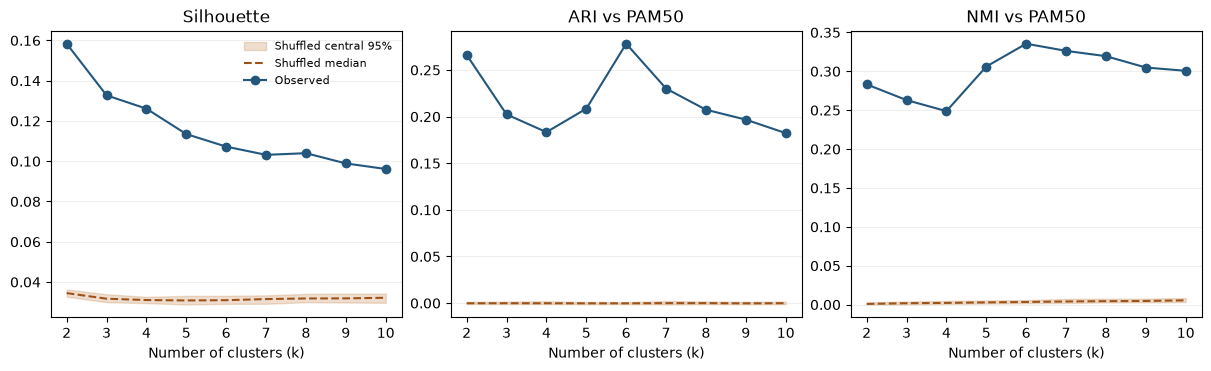

In [7]:
metric_titles = {"silhouette": "Silhouette", "ari": "ARI vs PAM50", "nmi": "NMI vs PAM50"}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")

for ax, metric in zip(axes, METRICS):
    rows = summary.xs(metric, level="metric")
    k = rows.index.to_numpy()
    ax.fill_between(
        k, rows["null_2.5%"], rows["null_97.5%"], alpha=0.22, color="#b76b25",
        label="Shuffled central 95%",
    )
    ax.plot(k, rows["null_median"], linestyle="--", color="#9d5318", label="Shuffled median")
    ax.plot(k, rows["observed"], marker="o", color="#23577e", label="Observed")
    ax.set(title=metric_titles[metric], xlabel="Number of clusters (k)", xticks=k)
    ax.grid(axis="y", alpha=0.2)

axes[0].legend(frameon=False, fontsize=8)
plt.show()

In [8]:
for k in (2, 5):
    above_interval = [
        metric_titles[metric] for metric in METRICS
        if summary.loc[(k, metric), "observed"] > summary.loc[(k, metric), "null_97.5%"]
    ]
    labels = ", ".join(above_interval) if above_interval else "none"
    print(f"k = {k} | Observed scores above the shuffled 97.5th percentile: {labels}")

print(
    "This comparison assesses cluster separation and PAM50 agreement against the gene-wise shuffle. "
    "Cohort effects and overlap with the PAM50 gene panel are separate sensitivity questions."
)

k = 2 | Observed scores above the shuffled 97.5th percentile: Silhouette, ARI vs PAM50, NMI vs PAM50
k = 5 | Observed scores above the shuffled 97.5th percentile: Silhouette, ARI vs PAM50, NMI vs PAM50
This comparison assesses cluster separation and PAM50 agreement against the gene-wise shuffle. Cohort effects and overlap with the PAM50 gene panel are separate sensitivity questions.
